In [34]:
# import libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import math
import pandas as pd

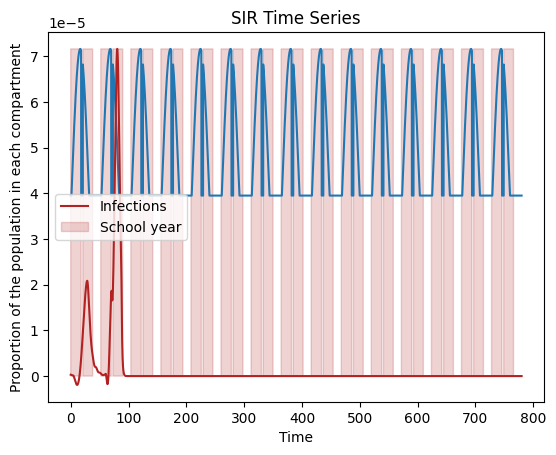

In [35]:
%matplotlib inline

# Define the function that determines the seasonality of the model
# inputs: b0 = baseline infection rate, a scalar
#         b1 = amplitude of seasonality, a scalar
#         time = week number, a scalar
# output: beta = the rate of infection at time t
shift = -1.3
period = 38*0.8
def seasonality(b0, b1, time):
    return b0 + b1 * max(math.sin(math.pi*((time +shift)%52)/period), 0) + 0.0
    
# inputs: t = time, a scalar,
#         startconds = initial conditions, a list
#         parms = parameters for the model, a dictionary
# outputs: a list of dS, dI, dR, rates of change of S, I, and R
def sirmod(t, startconds, parms): 
    # get initial conditions
    S = startconds[0]
    I = startconds[1]
    R = startconds[2]
    # get parameters
    beta0 = parms[0] # baseline infection rate
    beta1 = parms[1] # amplitude of seasonality
    mu = parms[2] # birth rate
    gamma = parms[3] # recovery rate
    v = parms[4] # vaccination rate

    # determine infectiousness based on whether school is in session
    if t%52 <= 18 or (t%52 >= 21 and t%52 <= 38):
        beta = seasonality(beta0, beta1, t) # use a sinusoidal function because measles is more infectious in winter
    else:
        beta = beta0

    # SCENARIOS FOR LONG-RUN VACCINATION
    if t > 87:
        # v = parms[5]
        # SCENARIO 3: keep decreasing at this rate
        v = 0.000001824405658 * (78007* (0.469 * (0.01917806642*(t-14) + 89.4)) + 20955*(0.064*(0.01917806642*(t-14) + 95.1)) + 387729*(0.356*(0.01917806642*(t-14) + 93.9)) + 44989*(0.719*(0.01917806642*(t-14) + 88.4)))
    
    
    # use system of ODEs to calculate dS, dI, dR
    dS = (1 - v) * mu - beta * S * I - mu * S
    dI = beta * S * I - gamma * I - mu * I
    dR = v * mu + gamma * I - mu * R
    
    # make sure no compartment is negative
    if S <= 0:
        dS = abs(S)
    if I <= 0:
        dI = abs(I)
    if R <= 0:
        dR = abs(R)
    res = [dS, dI, dR]
    
    return res # return dS, dI, dR

# inputs into the model
t_span = (0, 15*52) # time we're running the model. units = weeks
x_max = 15*52
t_eval = np.arange(0, x_max, 1/50) # time we're outputting. units = weeks
beta0 = 8 # baseline infectiousness. value of beta when school is not in session
beta1 = 6.5 # amplitude of seasonality when school is in session
# v_new = 0.9702 # SCENARIO 2: best case scenario
parms = [beta0, beta1, 0.001923, 0.875, 0.91278, v_new] # parameters. in order: beta0, beta1, mu, gamma, v_old, v_new
# vax rate assuming 99% effectiveness: 0.91278
# vax rate with 99% effectiveness: 0.89434
# birth rate when looking at under 10 population: 0.001923. This equals 1/10*52, or how many people enter the 1-10 age group per week
S = 1 - 0.91278 # initial immunity -- we base this on kindergarten vax rate
R = 1 - 0.0000003 - S # how many initial infections we start with
startconds = np.array([S, 0.0000003, R]) # in order: S, I, R
# run the model
sol = solve_ivp(sirmod, t_span, startconds, t_eval=t_eval, args = (parms,))

# Calculate R0
# get list of beta values depending on seasonality
beta = [seasonality(beta0, beta1, t) if t%52 <= 18 or (t%52 >= 21 and t%52 <= 38) else beta0 for t in sol.t]
# get list of R0 values by dividing by gamma
R0 = [b/parms[3] for b in beta]
# normalize R0 to plot it
R0_norm = [r*max(sol.y[1])/max(R0) for r in R0]
# plot normalized R0
plt.plot(sol.t, R0_norm)

# plt.plot(sol.t, sol.y[0], color = "dodgerblue", label = "S")
plt.plot(sol.t, sol.y[1], color = "firebrick", label = "Infections")
# plt.plot(sol.t, sol.y[2], color = "purple", label = "R")
ticks = np.arange(min(sol.t), max(sol.t), 2*52)
plt.fill_between(sol.t, np.linspace(max(sol.y[1]), max(sol.y[1]), len(sol.t)), 0, where = [t%52 <= 18 or (t%52 >= 21 and t%52 <= 38) for t in sol.t], color = "firebrick", alpha = 0.2, label = "School year")
plt.xlabel("Time")
plt.ylabel("Proportion of the population in each compartment")
plt.title("SIR Time Series")
plt.legend()
plt.show()

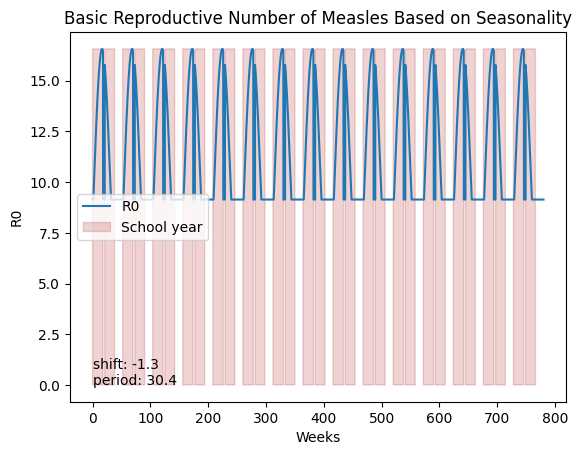

In [36]:
# determine infectiousness based on whether school is in session
# Calculate R0
# get list of beta values depending on seasonality
betas = [seasonality(beta0, beta1, t) if t%52 <= 18 or (t%52 >= 21 and t%52 <= 38) else beta0 for t in sol.t]
# get list of R0 values by dividing by gamma
R0 = [b/parms[3] for b in betas]

plt.annotate(f"shift: {shift}\nperiod: {np.round(period, 5)}", xy = (0,0))


plt.plot(sol.t, R0, label = "R0")
plt.fill_between(sol.t, np.linspace(max(R0), max(R0), len(sol.t)), 0, where = [t%52 <= 18 or (t%52 >= 21 and t%52 <= 38) for t in sol.t], color = "firebrick", alpha = 0.2, label = "School year")
plt.title("Basic Reproductive Number of Measles Based on Seasonality")
plt.ylabel("R0")
plt.xlabel("Weeks")
plt.legend()
# plt.savefig("fixed3_R0.png")

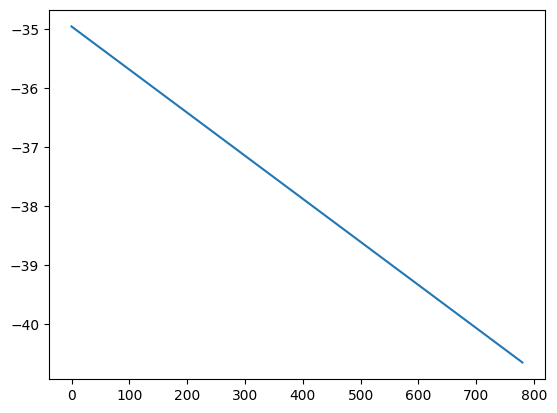

In [41]:
plt.plot(sol.t, [-0.000001824405658 * (78007* (0.469 * (0.01917806642*(t-14) + 89.4)) + 20955*(0.064*(0.01917806642*(t-14) + 95.1)) + 387729*(0.356*(0.01917806642*(t-14) + 93.9)) + 44989*(0.719*(0.01917806642*(t-14) + 88.4))) for t in sol.t])

Text(0.5, 1.0, 'Measles Cases in Population Ages 0-10')

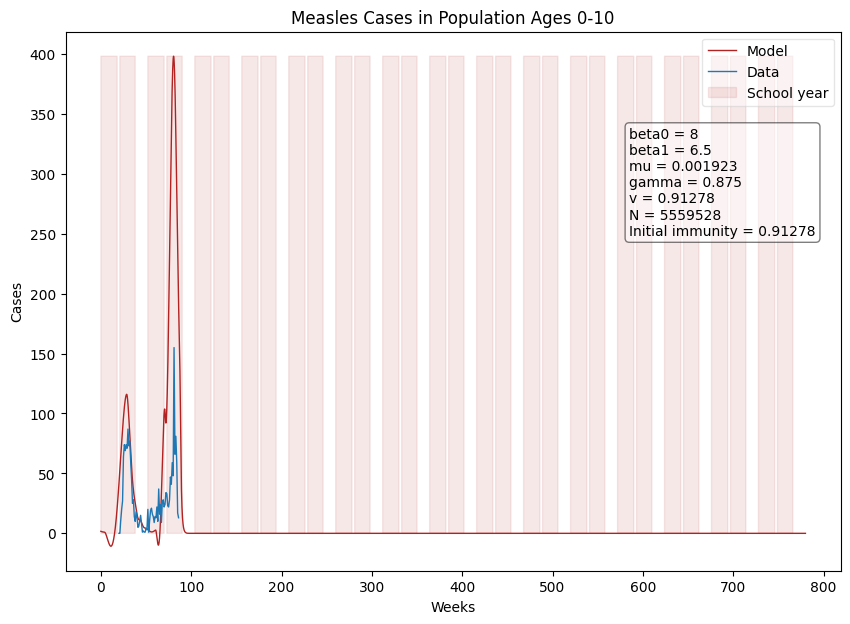

In [37]:
# GET DATA
cases = pd.read_csv("cases.txt", sep = "\t")
# TIME SCALE
t = np.linspace(min(sol.t), max(sol.t), len(cases))


# CONVERT FROM PROPORTION TO FULL NUMBER
# normalizing = 43466750 # TOTAL POPULATION
# normalizing = 19462518 # POPULATION IN AFFECTED COUNTIES
normalizing = 5559528 # POPULATION UNDER 10
# normalizing = (max(cases["Cases"]) - min(cases["Cases"]))/(max(sol.y[1]) - min(sol.y[1]))

# find maximum y value of either data or simulation. Need this to plot school year
y_max = max(max(cases["Cases"]), max(normalizing*sol.y[1]))

plt.figure(figsize = (10, 7))

# PLOT MODEL AND DATA
plt.plot(sol.t, normalizing*sol.y[1], color = "firebrick", label = "Model", lw = 1)
plt.plot(range(20, 20 + len(cases)), cases["Cases"], label = "Data", lw = 1) # plot data and model on same time scale
# plt.plot(t, cases["Cases"], label = "Data") # plot data and model on overlapping time scales
# annotate with parameters
plt.annotate(
    f"beta0 = {parms[0]}\nbeta1 = {parms[1]}\nmu = {parms[2]}\ngamma = {parms[3]}\nv = {parms[4]}\nN = {normalizing}\nInitial immunity = {np.round(R, decimals = 5)}",
    xy = ((6/8)*max(t), max(max(cases["Cases"]), max(normalizing*sol.y[1]))*(5/8)),
    bbox=dict(boxstyle='round', fc='white', alpha = 0.5)
)

# UNCOMMENT THIS TO SHOW CHANGING VACCINATION RATE SCENARIO
# # annotate the change in vax rate
# plt.annotate('Vaccination rate increases to 98%', xy=(87, (6/8)*y_max),
#              xytext=(87 + (1/10)*(max(t) - 87), (5/8)*y_max),
#              arrowprops=dict(arrowstyle= '-|>',
#                              color='darkslateblue',
#                              lw=2,
#                              ls='-'))
# # Plot line of changing vax rate
# x_span = np.linspace(87, 87, 100)
# y_span = np.linspace(0, y_max, 100)
# plt.plot(x_span, y_span, color = "darkslateblue")

# PLOT SCHOOL YEAR
plt.fill_between(sol.t, np.linspace(y_max, y_max, len(sol.t)), 0, where = [t%52 <= 18 or (t%52 >= 21 and t%52 <= 38) for t in sol.t], color = "firebrick", alpha = 0.1, label = "School year")

# FORMAT
plt.xlabel("Weeks")
plt.ylabel("Cases")
leg = plt.legend(loc = "upper right")
frame = leg.get_frame()
frame.set_facecolor("white")
frame.set_alpha(0.5)
plt.title("Measles Cases in Population Ages 0-10")
# plt.savefig("vax_best.png")

Text(0.06666901437949299, 0.0007824465975843468, 'beta0 = 9\nbeta1 = 4\nmu = 0.001923\ngamma = 0.875\nv = 0.91278\nN = 5559528')

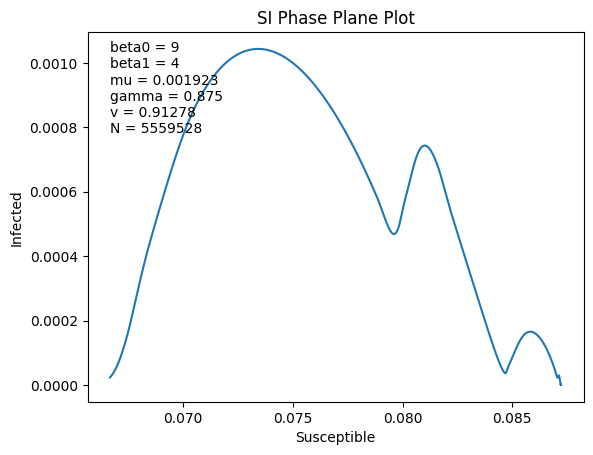

In [75]:
plt.plot(sol.y[0], sol.y[1])
plt.title("SI Phase Plane Plot")
plt.xlabel("Susceptible")
plt.ylabel("Infected")
plt.annotate(
    f"beta0 = {parms[0]}\nbeta1 = {parms[1]}\nmu = {parms[2]}\ngamma = {parms[3]}\nv = {parms[4]}\nN = {normalizing}",
    xy = (min(sol.y[0]), max(sol.y[1])*(6/8))
)